In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import pandas as pd
from matplotlib.colors import LogNorm, BoundaryNorm,ListedColormap
import matplotlib.patches as patches
from matplotlib.ticker import FixedLocator

import math
import os
import sys

if os.path.isdir("shared_python"):
    os.chdir("shared_python")

os.makedirs("../data", exist_ok=True)
os.makedirs("../figures", exist_ok=True)
sys.path.insert(0, os.path.abspath("../Code_main"))

In [ ]:
# Error_r_Var_uptopeak = np.load( "Error_r_Var_uptopeak.npy")
Error_r_Var_uptopeak = np.load( "../Data/Error_r_Var_uptopeak_truncatedH.npy")
sigma_values = np.arange(0,1.1,0.1)
delta_t_values = [ 0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100, 120, 140, 150, 160, 180, 200, 220, 240, 250]


In [5]:
print (Error_r_Var_uptopeak.shape)

OURZERO=-5
model_name=[
    "Zero order truncation",
    "1st order truncation",
    "2nd order truncation",
    "One variant at the time",
    "Two variants at the time"
]
delta_t_sel = [0, 5, 10, 15, 20, 25, 30, 50, 100, 150, 200, 250]
delta_t_index = [np.where(np.array(delta_t_values) == t)[0][0] for t in delta_t_sel]
variant_used= [0,1,2,3]

Error_sel= Error_r_Var_uptopeak[:, delta_t_index, :,:]
Error_sel[Error_sel<10**(OURZERO)] = 10**(OURZERO) 
print (Error_sel.shape)

possible_model_min=set()
label_model_min_t={
    '':0,
    'Zero order truncation':1, 
    '1st order truncation':2, 
    '2nd order truncation':3
}
label_model_min_o={
    '':0,
    'One variants at the time':1, 
    'Two variants at the time':2, 
}
model_min_t= np.zeros((12, 11, 4))
model_min_o= np.zeros((12, 11, 4))

for var_ind in variant_used:
    print ("\nVARIANT", var_ind+1)
    err_var = Error_sel[[0,1,2,3,4], :, :, var_ind]
    for t,deltat in enumerate(delta_t_sel):
        for s,sigma in enumerate(sigma_values):
            min= np.nanmin(err_var[:,t,s])
            model_min=[]
            
            min_log = math.log10(min)
            min_order = math.floor(min_log)
            for m, m_name in enumerate(model_name):
                if err_var[m,t,s]<min+2*10**(min_order-1):
                    if err_var[m,t,s]>min-2*10**(min_order-1):
                        model_min.append(m_name)
           
            possible_model_min.add(tuple(model_min))
            if '2nd order truncation' not in model_min:
                model_min_t[t,s,var_ind]=0
            elif '1st order truncation' not in model_min:
                model_min_t[t,s,var_ind]=3
            elif 'Zero order truncation' not in model_min:
                model_min_t[t,s,var_ind]=2
            else:
                model_min_t[t,s,var_ind]=1

            if 'One variant at the time' in model_min:
                model_min_o[t,s,var_ind]=1
            elif 'Two variants at the time' in model_min:
                model_min_o[t,s,var_ind]=2
            else:
                model_min_o[t,s,var_ind]=0

            if ('One variant at the time' in model_min):
                print (deltat,sigma,min,model_min)

print ("set of possible model mins")
for pmm in possible_model_min:
    print (pmm)

# print (Error_sel[ :,10,5,0])
# print (Error_sel[ :,9,3,0])

(5, 21, 11, 4)
(5, 12, 11, 4)

VARIANT 1
5 0.0 1e-05 ['Zero order truncation', '1st order truncation', '2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.1 1e-05 ['1st order truncation', '2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.2 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.30000000000000004 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.4 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.5 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.6000000000000001 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.7000000000000001 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.8 1e-05 ['2nd order truncation', 'One variant at the time', 'Two variants at the time']
5 0.9 1e-05 

<>:64: SyntaxWarning: invalid escape sequence '\D'
<>:117: SyntaxWarning: invalid escape sequence '\D'
<>:64: SyntaxWarning: invalid escape sequence '\D'
<>:117: SyntaxWarning: invalid escape sequence '\D'
/var/folders/4y/b5l83m955tx_n7j8wl85c97h0000gn/T/ipykernel_51160/890491347.py:64: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta t$", fontsize=18)
/var/folders/4y/b5l83m955tx_n7j8wl85c97h0000gn/T/ipykernel_51160/890491347.py:117: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta t$", fontsize=18)
/var/folders/4y/b5l83m955tx_n7j8wl85c97h0000gn/T/ipykernel_51160/890491347.py:64: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta t$", fontsize=18)
/var/folders/4y/b5l83m955tx_n7j8wl85c97h0000gn/T/ipykernel_51160/890491347.py:117: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta t$", fontsize=18)


ValueError: The number of FixedLocator locations (6), usually from a call to set_ticks, does not match the number of labels (5).

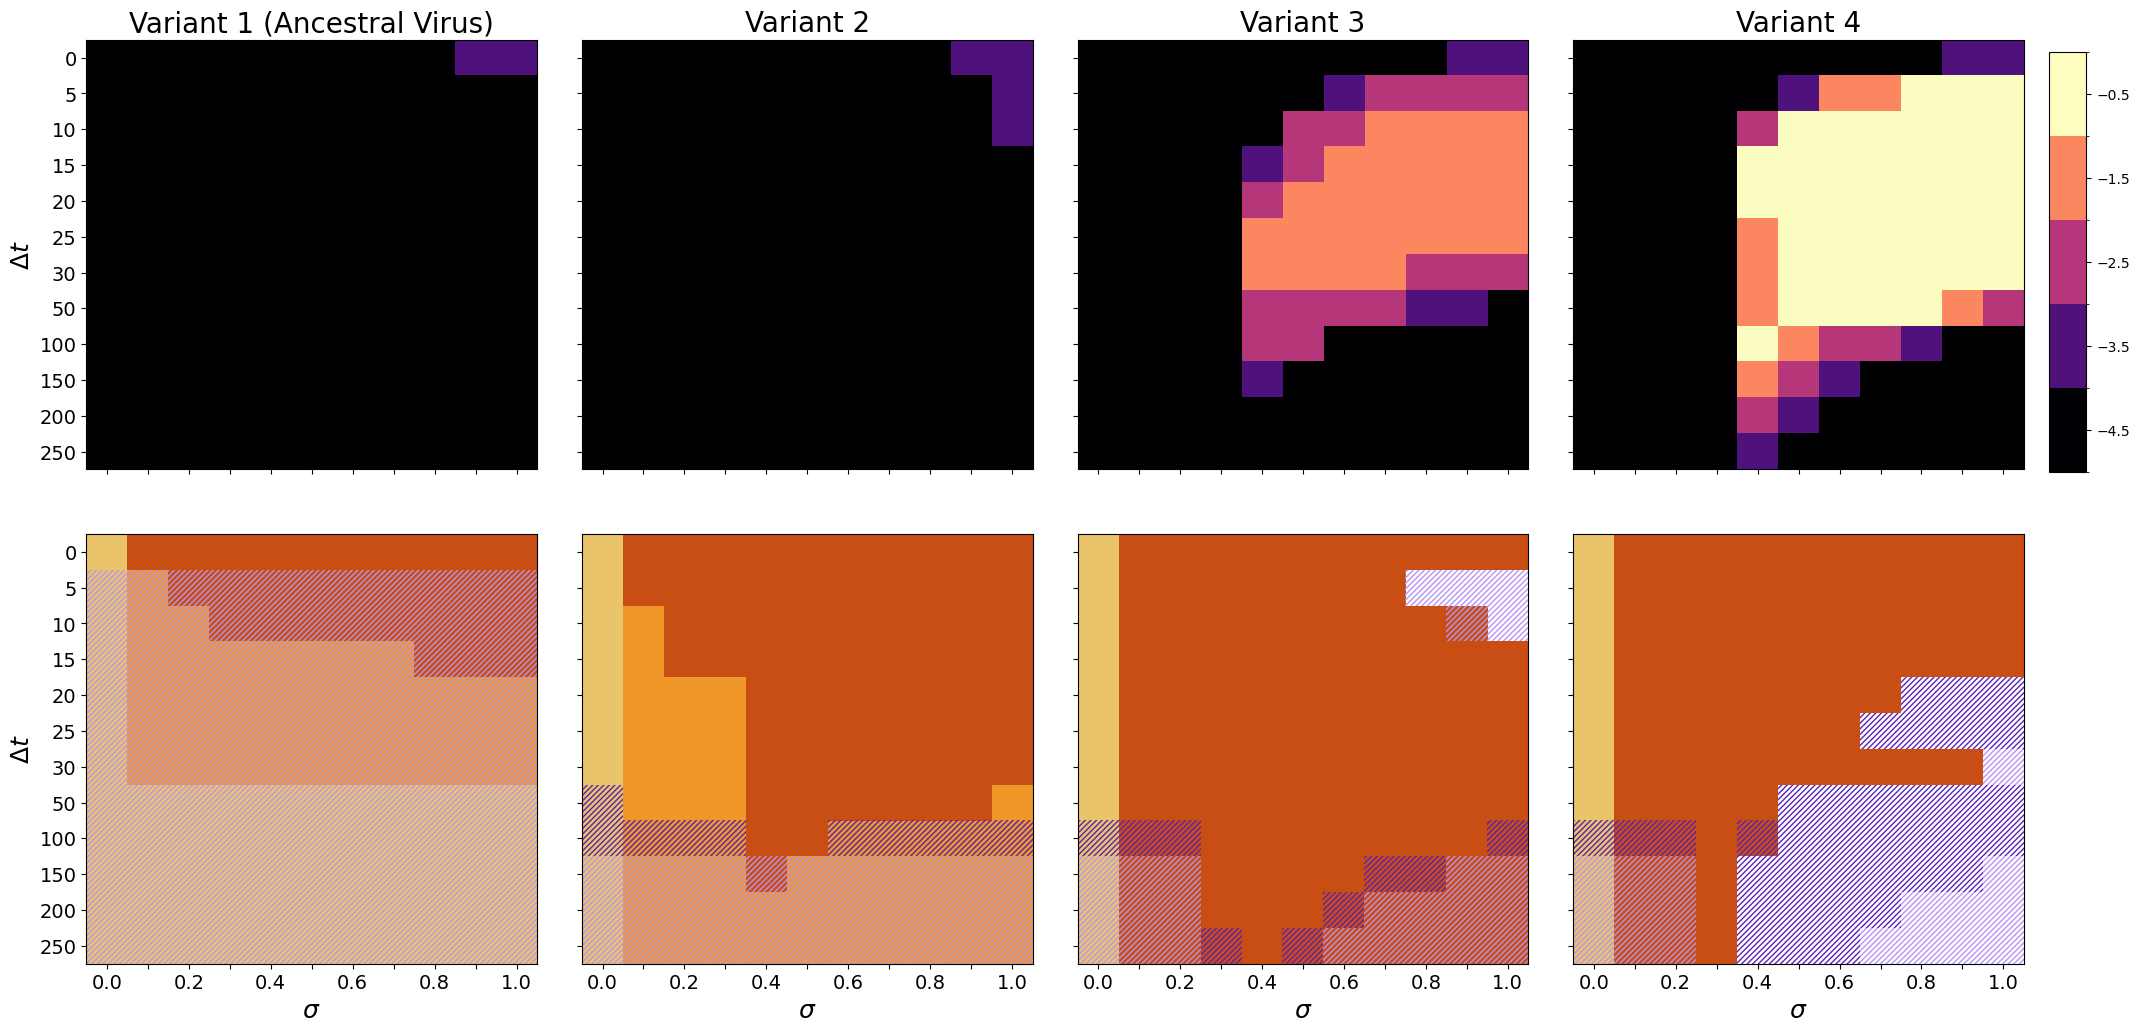

In [ ]:
import matplotlib.patches as mpatches


variant_labels = ['Variant 1 (Ancestral Virus)', 'Variant 2', 'Variant 3', 'Variant 4']
fig, axes = plt.subplots(2, 4, figsize=(25, 12), sharex=True)
axes = np.atleast_2d(axes)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

#error min plot
vmin = OURZERO
vmax = 0
boundaries = np.arange(vmin, vmax + 1, 1)  
error_cmap = plt.cm.magma
error_norm = BoundaryNorm(boundaries, error_cmap.N)

#model error min plot
method_colors = ["#FFFFFF", "#E9C46A", "#F09729", "#C84E13"]
method_cmap = ListedColormap(method_colors)
method_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), method_cmap.N)

#axes
delta_t_ticklabels = delta_t_sel
sigma_ticklabels = [i/10 if i % 2 == 0 else '' for i in range(len(sigma_values))]

# ----------------------------
# ROW 1: Minimum Error Heatmaps
# ----------------------------

for var_ind, var_name in enumerate(variant_labels):
    y = np.nanmin(Error_sel[[0, 1, 2, 3, 4], :, :, var_ind],axis=0)
    ylog= np.zeros((12, 11))

    for i in range(y.shape[0]):      
        for j in range(y.shape[1]): 
            y_log = math.log10(y[i,j])
            y_order = math.floor(y_log)
            ylog[i,j]= y_order

    ax = axes[0, var_ind]

    im_error = ax.imshow(
        ylog,
        aspect='auto',
        norm=error_norm,
        cmap='magma',
        origin='upper'
    )

    ax.set_title(var_name, fontsize=20)

    # X ticks
    ax.set_xticks(np.arange(len(sigma_values)))
    ax.set_xticklabels(np.round(sigma_values, 2), rotation=90, fontsize=10)

    # Y ticks
    ax.set_yticks(np.arange(len(delta_t_sel)))
    if var_ind == 0:
        ax.set_yticklabels(delta_t_ticklabels, rotation=0, fontsize=14)
        #ax.set_ylabel('The minimum error', fontsize=18)
    else:
        ax.set_yticklabels([])

    if var_ind==0:
        ax.set_ylabel("$\Delta t$", fontsize=18)  

# ----------------------------
# ROW 2: Best Method Heatmaps
# ----------------------------

for var_ind, var_name in enumerate(variant_labels[:4]):
    y=model_min_t[:,:,var_ind]
    ax = axes[1, var_ind]

    im_method = ax.imshow(
        y,
        aspect='auto',
        cmap=method_cmap,
        norm=method_norm,
        origin='upper'
    )

    for i in range(model_min_o.shape[0]):     
        for j in range(model_min_o.shape[1]):  
            if model_min_o[i, j, var_ind] ==1:
                ax.add_patch(mpatches.Rectangle(
                    xy=(j - 0.5, i - 0.5),  # bottom-left corner of cell
                    width=1,
                    height=1,
                    hatch='//////',
                    fill=False,
                    edgecolor="#B794F4",
                    linewidth=0
                ))
            elif model_min_o[i, j, var_ind] == 2:
                 ax.add_patch(mpatches.Rectangle(
                    xy=(j - 0.5, i - 0.5),  # bottom-left corner of cell
                    width=1,
                    height=1,
                    hatch='//////',
                    fill=False,
                    edgecolor="#5B21B6",
                    linewidth=0
                ))
    # X ticks
    ax.set_xticks(np.arange(len(sigma_values)))
    ax.set_xticklabels(sigma_ticklabels, rotation=0, fontsize=14)

    # Y ticks
    ax.set_yticks(np.arange(len(delta_t_sel)))
    if var_ind == 0:
        ax.set_yticklabels(delta_t_ticklabels, rotation=0, fontsize=14)
    else:
        ax.set_yticklabels([])

    ax.set_xlabel(r"$\sigma$", fontsize=18)
    if var_ind==0:
        ax.set_ylabel("$\Delta t$", fontsize=18)        

# ------------------
# COLORBAR 1: Error 
# ------------------

cax_error = fig.add_axes([0.91, 0.52, 0.015, 0.35])
cbar_error = fig.colorbar(
    im_error,
    cax=cax_error,
    ticks=np.arange(vmin+0.5, vmax + 1, 1)  # one tick per integer
)
cbar_error.set_ticklabels([
    # r"$<10^{-6}$",
    # r"$10^{-5}$",
    r"$10^{-4}$",
    r"$10^{-3}$",
    r"$10^{-2}$",
    r"$10^{-1}$",
    r"$10^{0}$"
])
cbar_error.ax.set_title("Minimum error", fontsize=20, y=1.05)

# -------------------
# COLORBAR 2: Method 
# -------------------
cax_method = fig.add_axes([
    0.91,   # x position
    0.22,   # y position
    0.015,  # width
    0.25    # height
])
cbar_method = fig.colorbar(
    im_method,
    cax=cax_method,
    ticks=np.arange(4)
)
cbar_method.set_ticklabels([
    "none",
    "Zero order \ntruncation",
    "1st order \ntruncation",
    "2nd order \ntruncation",
])
cbar_method.ax.set_title("Best method", fontsize=20, y=1.05, rotation=0)

# --------------
# HATCH LEGEND 
# --------------
hatch_legend_elements = [
    mpatches.Patch(
        facecolor='white',
        edgecolor="#B794F4",
        hatch='//////',
        label='One variant at the time'
    ),
    mpatches.Patch(
        facecolor='white',
        edgecolor="#5B21B6",
        hatch='//////',
        label='Two variants at the time'
    ),
    mpatches.Patch(
        facecolor='white',
        edgecolor='black',
        hatch='',
        label='None'
    ),
]

# Aligned with colorbar 2 (same x position and width)
legend_ax = fig.add_axes([
    0.905,  # same x as colorbar 2
    0.12,   # just below colorbar 2
    0.06,   # same width as colorbar 2
    0.08    # height
])
legend_ax.axis('off')

legend = legend_ax.legend(
    handles=hatch_legend_elements,
    loc='upper left',
    ncol=1,             # vertical layout
    fontsize=10,
    #title='Hatching',
    #title_fontsize=11,
    frameon=False,      # no border
    handlelength=2,
    handleheight=1.5,
    bbox_to_anchor=(0.0, 1.0)  # aligned to top-left of legend_ax
)

# plt.savefig('../figures/minimum-error.png',bbox_inches='tight',dpi=300,transparent=False, format='png')
#plt.show()